# 3. Model Inference
This stage is used for inference, where the trained and evaluated YOLO model is applied to raster data in **uint8** format. <br>


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install ultralytics
!pip install geopandas
!pip install rasterio
!pip install shapely
!pip install numpy
!pip install opencv-python
!pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 601.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.6 MB/s eta 0:00:00


In [3]:
# Import necessary libraries
import rasterio
from rasterio.plot import show
import numpy as np
import cv2
import geopandas as gpd
from shapely.geometry import Point
from PIL import Image
import time
import os
import matplotlib.pyplot as plt
from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [4]:
# Function to convert bounding box coordinates to geographic coordinates
def bbox_to_geo(bbox, transform):
    x_center, y_center = bbox
    x_center_geo, y_center_geo = rasterio.transform.xy(transform, y_center, x_center)
    return (x_center_geo, y_center_geo)

# Function to split image into tiles
def split_image(image, tile_size):
    img_width, img_height = image.size
    tiles = []
    for y in range(0, img_height, tile_size):
        for x in range(0, img_width, tile_size):
            box = (x, y, x + tile_size, y + tile_size)
            tile = image.crop(box)
            tiles.append((tile, x, y))
    return tiles

# Function to apply YOLO model to raster image and generate GeoJSON output
def apply_model_to_raster(model, input_raster_path, output_geojson_path):
    start_time = time.time()

    # Check if input file exists
    if not os.path.exists(input_raster_path):
        raise FileNotFoundError(f"Input file not found: {input_raster_path}")

    # Open raster and read data
    print(f"Loading raster: {os.path.basename(input_raster_path)}")
    with rasterio.open(input_raster_path) as src:
        original_image = src.read([1, 2, 3])
        original_transform = src.transform
        original_crs = src.crs

        print(f"Image size: {src.height}x{src.width}")
        print(f"CRS: {original_crs}")

    # Convert from (bands, height, width) to (height, width, bands)
    original_image = np.moveaxis(original_image, 0, -1)
    original_height, original_width, _ = original_image.shape

    detection_points = []

    # Split image into tiles and run inference
    print("Processing tiles for detection...")
    tiles = split_image(Image.fromarray(original_image), 640)

    for idx, (tile, x_offset, y_offset) in enumerate(tiles):
        # Convert tile to array (already in RGB format from PIL)
        tile_array = np.array(tile)

        # Run YOLO inference
        results = model.predict(source=tile_array, verbose=False)

        # Extract bounding boxes and convert to geographic coordinates
        for box in results[0].boxes:
            x_min, y_min, x_max, y_max = box.xyxy[0]

            # Calculate center point in image coordinates
            x_center = int((x_min + x_max) / 2) + x_offset
            y_center = int((y_min + y_max) / 2) + y_offset

            # Convert bounding box center to geographic coordinates
            geo_point = bbox_to_geo([x_center, y_center], original_transform)
            detection_points.append(Point(geo_point))

        # Progress indicator
        if (idx + 1) % 10 == 0:
            print(f"Processed {idx + 1}/{len(tiles)} tiles...")

    # Create GeoDataFrame and save as GeoJSON
    print(f"\nSaving detection results to GeoJSON...")
    gdf = gpd.GeoDataFrame(geometry=detection_points, crs=original_crs)
    gdf.to_file(output_geojson_path, driver='GeoJSON')

    # Display the raster with detection points
    # Display the raster with detection points
    print("\nGenerating detection preview...")
    with rasterio.open(input_raster_path) as src:
        fig, ax = plt.subplots(figsize=(10, 14), dpi=150)
        show(src, ax=ax)

        # Scatter detections in one call — faster, better styling than loop
        xs = [p.x for p in detection_points]
        ys = [p.y for p in detection_points]
        ax.scatter(
            xs, ys,
            c='#ff3b30',          # softer red
            s=10,                 # slightly larger
            edgecolors='white',   # white outline → pops against any background
            linewidths=0.4,
            alpha=0.9,
        )

        ax.set_title(
            f'Oil Palm Detection — {len(detection_points):,} trees',
            fontsize=13, fontweight='bold', pad=10
        )
        ax.set_axis_off()

        plt.tight_layout()
        plt.savefig('final_results.png', dpi=200, bbox_inches='tight', facecolor='white')
        plt.show()

    # Print summary statistics
    print("\n" + "=" * 50)
    print("DETECTION SUMMARY")
    print("=" * 50)
    print(f"Number of oil palms detected: {len(detection_points)} trees")

    # Calculate total computation time
    end_time = time.time()
    print(f"Computation time: {end_time - start_time:.2f} seconds")

    # Print the size of the input data
    input_data_size = os.path.getsize(input_raster_path) / (1024 * 1024)  # Convert bytes to megabytes
    print(f"Processed raster data size: {input_data_size:.2f} MB")
    print(f"Output saved to: {output_geojson_path}")
    print("=" * 50)


In [6]:
# Define input and output paths
input_raster_path = r'/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/raster_data/raster_data_3_uint8.tif'
output_geojson_path = r'/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/output/oilpalm_detect_raster_data_3_yolo26n.geojson'

# Load the trained YOLO model
print("Loading YOLO model...")
model = YOLO(r'/content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/model/oilpalm_detection_model_yolov26n.pt')
print(f"Model loaded successfully. Device: {model.device}")

# Apply model to raster image
apply_model_to_raster(model, input_raster_path, output_geojson_path)


Output hidden; open in https://colab.research.google.com to view.

## Post-processing: Remove Closely-Spaced Detections

In commercial oil palm plantations, trees are planted with a fixed spacing (typically 8 to 9 meters between trees). Detections that fall within an unrealistically short distance of each other are therefore likely to be duplicates produced by overlapping tiles or imperfect non-maximum suppression. The cell below removes these by keeping only one point per cluster within a configurable distance threshold (default: 5 meters). Adjust `min_distance` based on the planting pattern of the AOI.

In [7]:
import geopandas as gpd
from scipy.spatial import cKDTree
import numpy as np

# Load the raw detection GeoJSON produced above
gdf = gpd.read_file(output_geojson_path)
print(f"Raw detections: {len(gdf)} points")

# Minimum allowable distance between two trees (in CRS units, assumed meters for a projected CRS)
min_distance = 5.0

# Build a KDTree over detection coordinates and greedily drop neighbors within min_distance
coords = np.array([(p.x, p.y) for p in gdf.geometry])
tree = cKDTree(coords)
keep = np.ones(len(coords), dtype=bool)

for i in range(len(coords)):
    if not keep[i]:
        continue
    neighbors = tree.query_ball_point(coords[i], r=min_distance)
    for j in neighbors:
        if j != i and keep[j]:
            keep[j] = False

gdf_filtered = gdf[keep].reset_index(drop=True)
print(f"After filtering (min_distance = {min_distance} m): {len(gdf_filtered)} points")
print(f"Removed: {len(gdf) - len(gdf_filtered)} points")

# Save the cleaned GeoJSON alongside the raw one
filtered_geojson_path = output_geojson_path.replace('.geojson', '_filtered.geojson')
gdf_filtered.to_file(filtered_geojson_path, driver='GeoJSON')
print(f"Filtered output saved to: {filtered_geojson_path}")

Raw detections: 4752 points
After filtering (min_distance = 5.0 m): 3939 points
Removed: 813 points
Filtered output saved to: /content/drive/MyDrive/PROJECT/oilpalm-tree-detection-yolov26/output/oilpalm_detect_raster_data_3_yolo26n_filtered.geojson


### Compare Results Before and After Post-processing

This section visually compares the detection results before and after the post-processing step (removing closely-spaced detections). We will select a few random locations from the input raster and display a zoomed-in view of the detections in those areas.

On the left, you will see the raw detections from the YOLO model, which might contain multiple overlapping points for a single tree, or points that are too close given typical planting patterns. On the right, you will see the filtered detections after applying the minimum distance threshold.

This comparison helps to assess the effectiveness of the post-processing in cleaning up redundant detections and providing a more accurate count and distribution of oil palm trees.

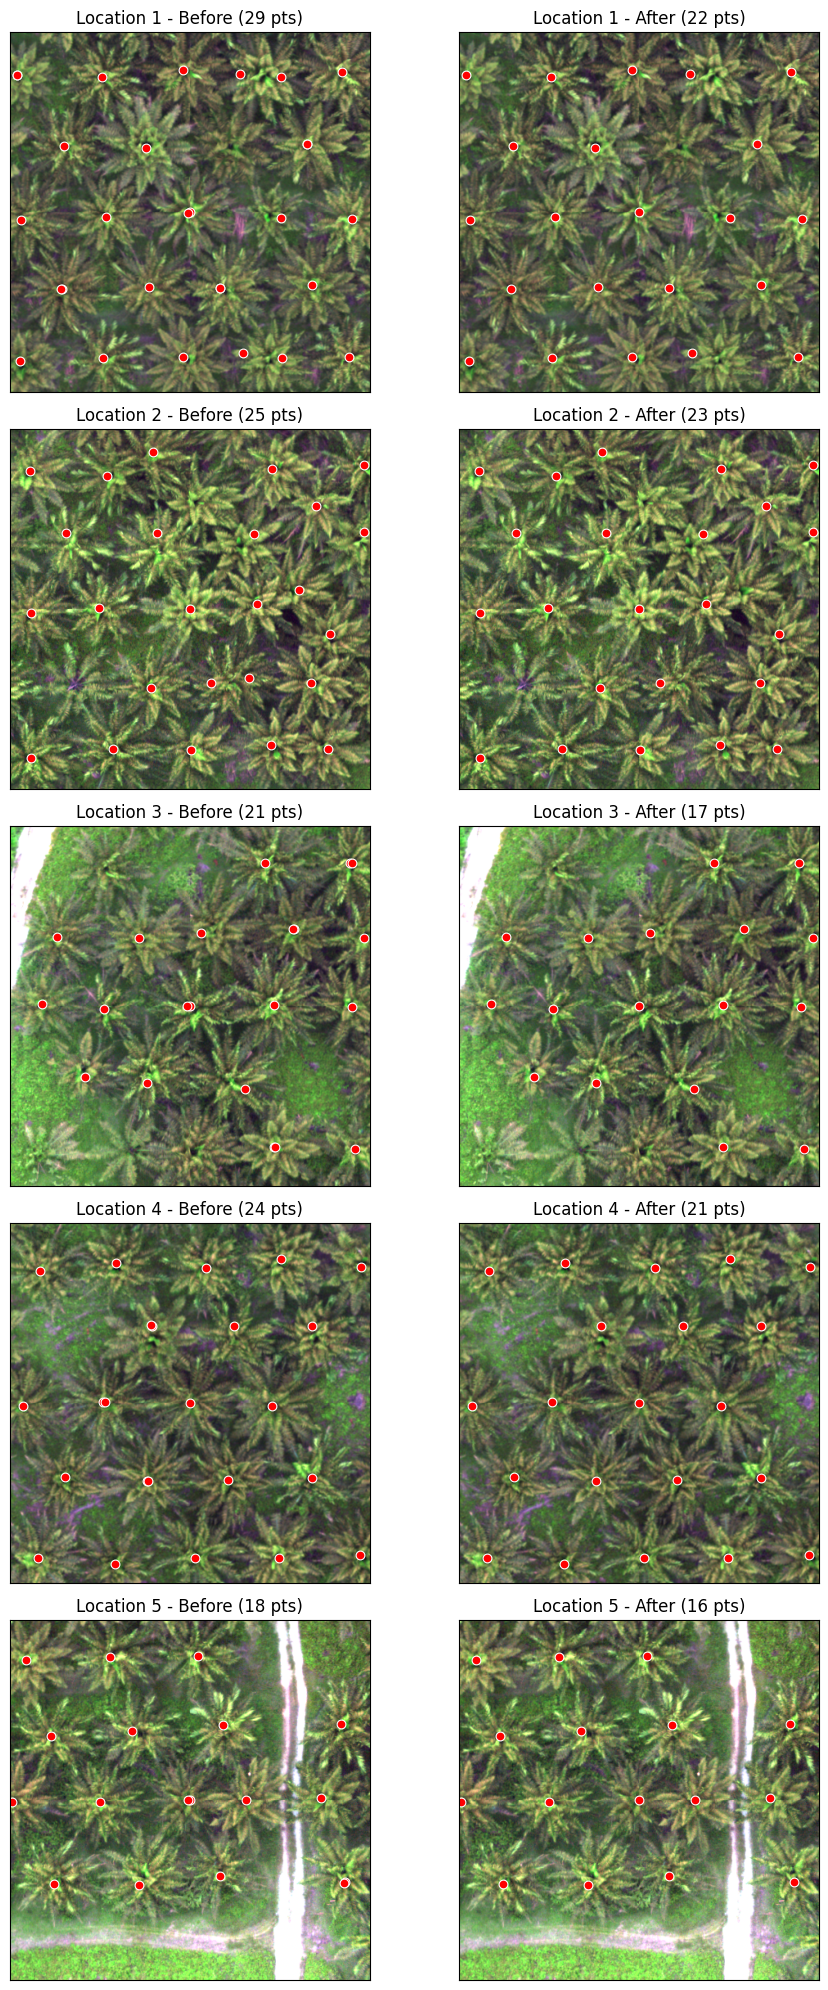

In [11]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
import numpy as np

# Window size around each sample location (in CRS units, meters for a projected CRS)
window_size = 40

# Pick 5 random raw-detection points as sample centers (fixed seed for reproducibility)
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(gdf), size=5, replace=False)
sample_points = gdf.iloc[sample_idx].reset_index(drop=True)

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

with rasterio.open(input_raster_path) as src:
    for row in range(5):
        cx, cy = sample_points.geometry[row].x, sample_points.geometry[row].y
        half = window_size / 2
        left, bottom, right, top = cx - half, cy - half, cx + half, cy + half

        # Read only the raster window covering this location
        window = from_bounds(left, bottom, right, top, src.transform)
        img = np.moveaxis(src.read([1, 2, 3], window=window), 0, -1)
        extent = (left, right, bottom, top)

        # Subset detections that fall inside this window
        raw_in  = gdf.cx[left:right, bottom:top]
        filt_in = gdf_filtered.cx[left:right, bottom:top]

        # Before
        axes[row, 0].imshow(img, extent=extent)
        axes[row, 0].scatter(raw_in.geometry.x, raw_in.geometry.y,
                             c='red', s=40, edgecolors='white', linewidths=0.8)
        axes[row, 0].set_title(f"Location {row+1} - Before ({len(raw_in)} pts)")
        axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])

        # After
        axes[row, 1].imshow(img, extent=extent)
        axes[row, 1].scatter(filt_in.geometry.x, filt_in.geometry.y,
                             c='red', s=40, edgecolors='white', linewidths=0.8)
        axes[row, 1].set_title(f"Location {row+1} - After ({len(filt_in)} pts)")
        axes[row, 1].set_xticks([]); axes[row, 1].set_yticks([])

plt.tight_layout()
plt.show()